# Hospital Readmission Analysis — 101,766 Real Encounters from 130 US Hospitals

**Goal:** answer practical hospital-management questions from real, de-identified hospital data and feed a dashboard.

**Data:** *Diabetes 130-US Hospitals for Years 1999–2008* — Clore, Cios, DeShazo & Strack (2014), UCI Machine Learning Repository,
[doi:10.24432/C5230J](https://doi.org/10.24432/C5230J), licence CC BY 4.0. Each row is one inpatient encounter of a patient with diabetes (stay of 1–14 days).

| # | Business question |
|---|---|
| Q1 | How is the hospital network doing at a glance? |
| Q2 | Who is admitted, and how? |
| Q3 | Which patient groups and conditions stay longer? |
| Q4 | Which patients are more likely to be readmitted within 30 days? |
| Q5 | Where do hospital resources (bed-days, tests, medications) go? |

> Findings describe associations in observational data — not medical advice and not proof of cause.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data" / "processed"
sns.set_theme(style="whitegrid", context="notebook")
BLUE, GREY, RED = "#2a6f97", "#9aa5b1", "#c8553d"
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(OUT / "hospital_encounters_clean.csv", low_memory=False)
elig = df[df.readmit_eligible]
AGES = ["Under 40", "40-49", "50-59", "60-69", "70-79", "80+"]
print(f"{len(df):,} encounters | {df.patient_nbr.nunique():,} patients | {elig.readmitted_30d.sum():,} readmissions within 30 days")
df.head()

101,763 encounters | 71,515 patients | 11,314 readmissions within 30 days


,encounter_id,patient_nbr,race,gender,age,age_group,age_mid,admission_type,admission_source,discharge_group,...,prior_inpatient_band,A1Cresult,a1c_tested,insulin,med_changed,diabetesMed,expired,readmitted,readmit_eligible,readmitted_30d
0,2278392,8222157,Caucasian,Female,[0-10),Under 40,5,Unknown,Referral,Unknown,...,0,NaN,False,No,False,No,False,NO,True,False
1,149190,55629189,Caucasian,Female,[10-20),Under 40,15,Emergency,Emergency Room,Home,...,0,NaN,False,Up,True,Yes,False,>30,True,False
2,64410,86047875,AfricanAmerican,Female,[20-30),Under 40,25,Emergency,Emergency Room,Home,...,1,NaN,False,No,False,Yes,False,NO,True,False
3,500364,82442376,Caucasian,Male,[30-40),Under 40,35,Emergency,Emergency Room,Home,...,0,NaN,False,Up,True,Yes,False,NO,True,False
4,16680,42519267,Caucasian,Male,[40-50),40-49,45,Emergency,Emergency Room,Home,...,0,NaN,False,Steady,True,Yes,False,NO,True,False


## 0. Data quality — what cleaning changed

In [2]:
pd.read_csv(OUT / "cleaning_log.csv")

,step,rows_affected,detail
0,Load raw file,101766,"101,766 encounters expected (UCI)"
1,'?' used as missing marker,192849,"cells; top columns: weight 98,569, medical_spe..."
2,Duplicate encounter_id,0,should be 0
3,Remove invalid gender,3,gender recorded as Unknown/Invalid
4,Drop weight,98566,96.9% missing - too sparse to use
5,Drop max_glu_serum,96417,94.7% missing - too sparse to use
6,Missing race,2271,2.2% - labelled 'Unknown'
7,Missing payer_code,40255,39.6% - labelled 'Unknown'
8,Missing medical_specialty,49947,49.1% - grouped as 'Not recorded'
9,Map coded IDs to labels,101763,"admission type, admission source, discharge di..."


**Class imbalance:** only ~11% of eligible encounters are 30-day readmissions, so rates within groups (not counts) are compared,
and the model is judged by AUC and lift, not accuracy (predicting "no readmission" for everyone would be ~89% accurate).
**Repeat patients:** 30,248 encounters belong to patients seen more than once, so the model's train/test split is grouped by patient to avoid leakage.

## Q1. At a glance

In [3]:
kpi = {
    "encounters": len(df),
    "unique_patients": int(df.patient_nbr.nunique()),
    "avg_los_days": round(df.length_of_stay.mean(), 2),
    "median_los_days": float(df.length_of_stay.median()),
    "readmit_eligible": int(df.readmit_eligible.sum()),
    "readmissions_30d": int(elig.readmitted_30d.sum()),
    "readmission_rate_30d_pct": round(elig.readmitted_30d.mean() * 100, 2),
    "mortality_pct": round(df.expired.mean() * 100, 2),
    "emergency_share_pct": round((df.admission_type == "Emergency").mean() * 100, 1),
    "a1c_tested_pct": round(df.a1c_tested.mean() * 100, 1),
    "total_bed_days": int(df.length_of_stay.sum()),
    "avg_medications": round(df.num_medications.mean(), 1),
    "avg_lab_procedures": round(df.num_lab_procedures.mean(), 1),
}
json.dump(kpi, open(OUT / "kpis.json", "w"), indent=2)
pd.Series(kpi).to_frame("value")

,value
encounters,101763.00
unique_patients,71515.00
avg_los_days,4.40
median_los_days,4.00
readmit_eligible,99340.00
readmissions_30d,11314.00
readmission_rate_30d_pct,11.39
mortality_pct,1.62
emergency_share_pct,53.10
a1c_tested_pct,16.70


## Q2. Who is admitted, and how?

,% of encounters by gender
gender,
Female,53.8
Male,46.2


,% of encounters by admission_type
admission_type,
Emergency,53.1
Elective,18.5
Urgent,18.2
Unknown,10.2
Other,0.0


,% of encounters by admission_source
admission_source,
Emergency Room,56.5
Referral,30.3
Other/Unknown,7.0
Transfer,6.2


,% of encounters by race
race,
Caucasian,74.8
AfricanAmerican,18.9
Unknown,2.2
Hispanic,2.0
Other,1.5
Asian,0.6


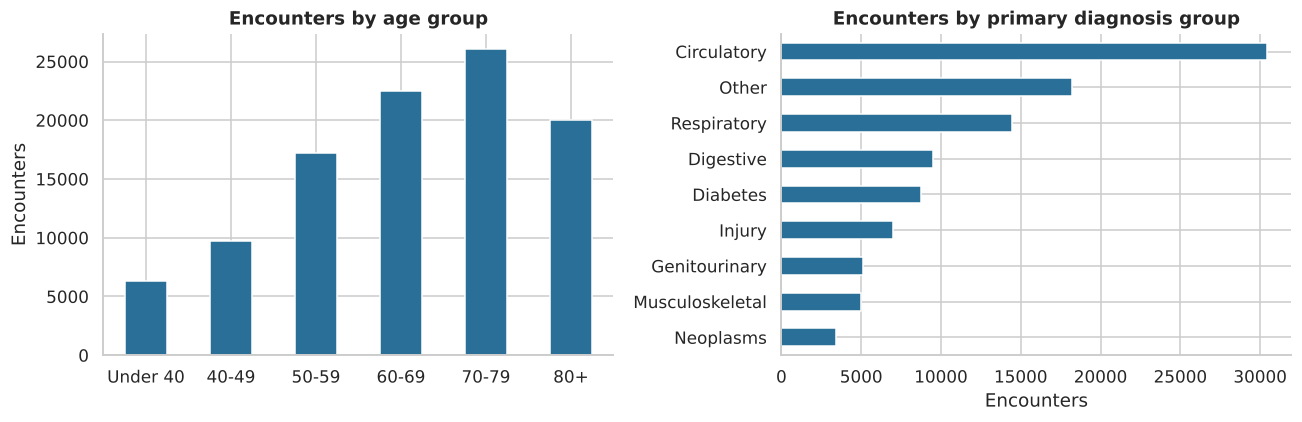

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.age_group.value_counts().reindex(AGES).plot.bar(ax=ax[0], color=BLUE)
ax[0].set(title="Encounters by age group", xlabel="", ylabel="Encounters"); ax[0].tick_params(axis="x", rotation=0)
df.diag_group.value_counts().sort_values().plot.barh(ax=ax[1], color=BLUE)
ax[1].set(title="Encounters by primary diagnosis group", xlabel="Encounters", ylabel="")
save(fig, "q2_admissions_age_diagnosis")
for col in ["gender", "admission_type", "admission_source", "race"]:
    display(df[col].value_counts(normalize=True).mul(100).round(1).to_frame(f"% of encounters by {col}"))

## Q3. Which patients and conditions stay longer?

,mean,median,size
age_group,,,
Under 40,3.64,3.0,6284
40-49,4.04,3.0,9685
50-59,4.13,3.0,17256
60-69,4.38,4.0,22482
70-79,4.59,4.0,26066
80+,4.80,4.0,19990


,encounters,avg_los,bed_days
diag_group,,,
Neoplasms,3433,5.36,18388
Other,18193,4.76,86656
Injury,6972,4.62,32186
Digestive,9475,4.36,41312
Diabetes,8757,4.34,38024
Genitourinary,5117,4.24,21696
Respiratory,14423,4.23,60993
Circulatory,30436,4.23,128666
Musculoskeletal,4957,3.92,19431


,mean,size
admission_type,,
Elective,4.32,18868
Emergency,4.38,54009
Other,3.20,10
Unknown,4.24,10396
Urgent,4.61,18480


OLS R² = 0.064 — most variation in stay length is not explained by these fields.


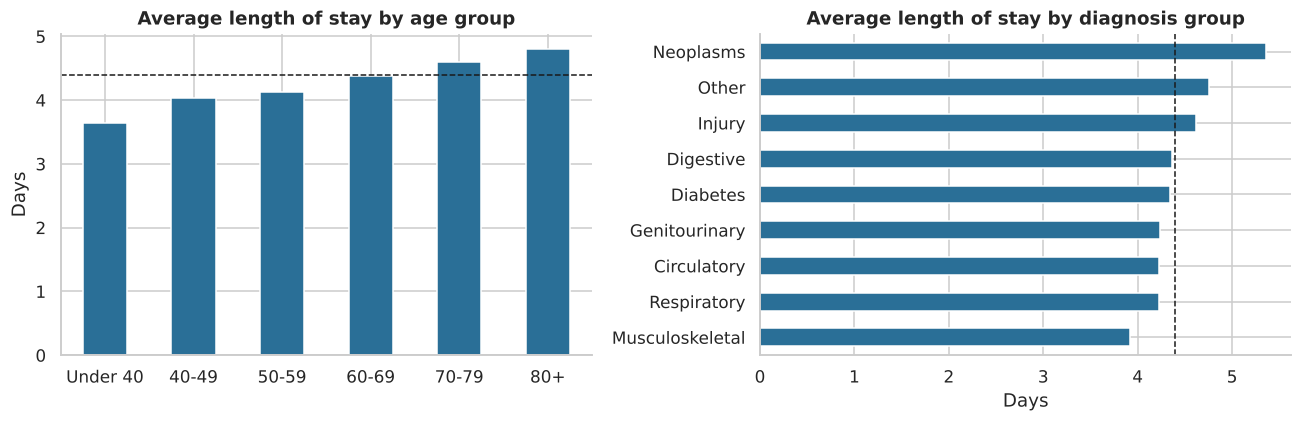

In [5]:
los_age = df.groupby("age_group").length_of_stay.agg(["mean", "median", "size"]).reindex(AGES)
los_diag = df.groupby("diag_group").agg(encounters=("encounter_id", "size"), avg_los=("length_of_stay", "mean"),
                                        bed_days=("length_of_stay", "sum")).sort_values("avg_los", ascending=False).round(2)
los_diag.to_csv(OUT / "summary_los_by_diagnosis.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
los_age["mean"].plot.bar(ax=ax[0], color=BLUE); ax[0].axhline(df.length_of_stay.mean(), color="k", ls="--", lw=1)
ax[0].set(title="Average length of stay by age group", xlabel="", ylabel="Days"); ax[0].tick_params(axis="x", rotation=0)
los_diag.avg_los.sort_values().plot.barh(ax=ax[1], color=BLUE); ax[1].axvline(df.length_of_stay.mean(), color="k", ls="--", lw=1)
ax[1].set(title="Average length of stay by diagnosis group", xlabel="Days", ylabel="")
save(fig, "q3_los_age_diagnosis")
display(los_age.round(2)); display(los_diag)
display(df.groupby("admission_type").length_of_stay.agg(["mean", "size"]).round(2))
los_model = smf.ols("length_of_stay ~ C(age_group, Treatment('50-59')) + C(diag_group, Treatment('Circulatory')) + C(admission_type) + number_diagnoses", data=df).fit()
print(f"OLS R² = {los_model.rsquared:.3f} — most variation in stay length is not explained by these fields.")

## Q4. Who is readmitted within 30 days?

,encounters,readmissions,rate_pct
prior_inpatient_band,,,
0,66242,5690,8.6
1,18984,2516,13.3
2,7300,1309,17.9
3+,6814,1799,26.4


,encounters,readmissions,rate_pct
discharge_group,,,
Other facility,3546,677,19.1
Nursing/rehab facility,17221,2739,15.9
Left against advice,623,90,14.4
Home with care,13010,1653,12.7
Unknown,4680,551,11.8
Home,60232,5602,9.3
Other,28,2,7.1


,encounters,readmissions,rate_pct
diag_group,,,
Diabetes,8661,1135,13.1
Injury,6851,850,12.4
Circulatory,29680,3469,11.7
Other,17813,2084,11.7
Genitourinary,5002,552,11.0
Neoplasms,3131,341,10.9
Digestive,9333,1010,10.8
Respiratory,13934,1402,10.1
Musculoskeletal,4935,471,9.5


,encounters,readmissions,rate_pct
age_group,,,
Under 40,6263,703,11.2
40-49,9607,1024,10.7
50-59,17060,1667,9.8
60-69,22058,2493,11.3
70-79,25329,3054,12.1
80+,19023,2373,12.5


,encounters,readmissions,rate_pct
a1c_tested,,,
False,82506,9641,11.7
True,16834,1673,9.9


,encounters,readmissions,rate_pct
admission_type,,,
Emergency,52387,6194,11.8
Urgent,18132,2058,11.4
Unknown,10144,1103,10.9
Elective,18667,1958,10.5
Other,10,1,10.0


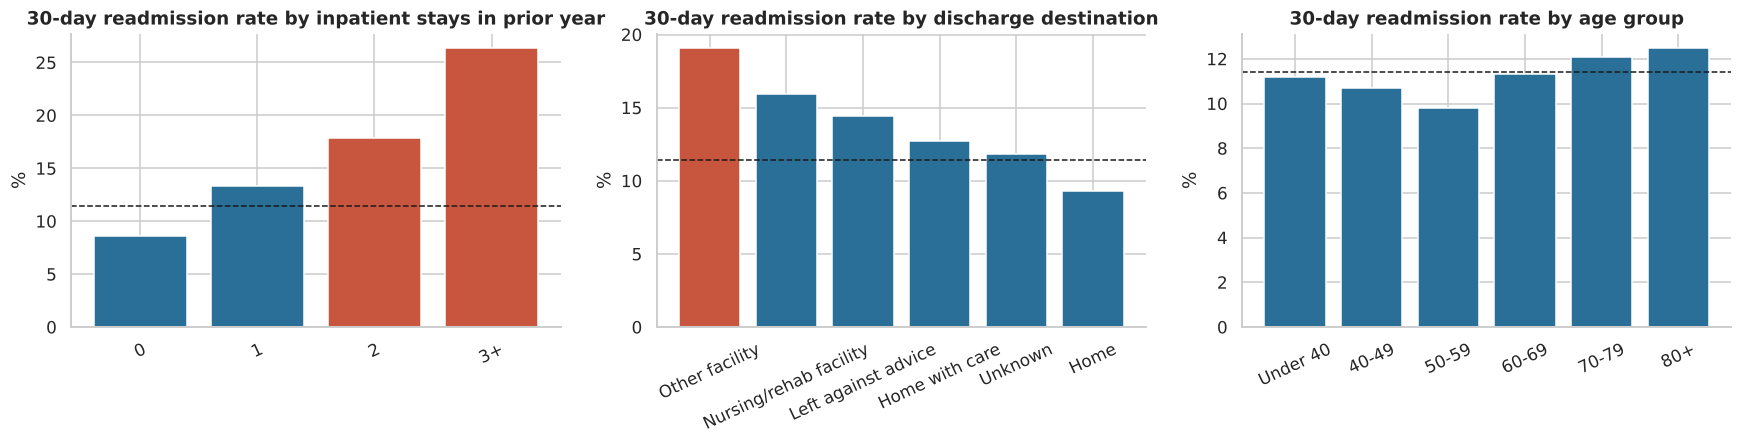

In [6]:
overall = elig.readmitted_30d.mean() * 100
def rate(col, order=None):
    t = elig.groupby(col).agg(encounters=("readmitted_30d", "size"), readmissions=("readmitted_30d", "sum"))
    t["rate_pct"] = (t.readmissions / t.encounters * 100).round(1)
    return t.reindex(order) if order else t.sort_values("rate_pct", ascending=False)
r_prior = rate("prior_inpatient_band", ["0", "1", "2", "3+"]); r_prior.to_csv(OUT / "summary_readmit_by_prior.csv")
r_disp = rate("discharge_group"); r_disp.to_csv(OUT / "summary_readmit_by_discharge.csv")
r_diag = rate("diag_group"); r_diag.to_csv(OUT / "summary_readmit_by_diagnosis.csv")
r_age = rate("age_group", AGES)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, (t, title) in zip(ax, [(r_prior, "by inpatient stays in prior year"), (r_disp[r_disp.encounters >= 500], "by discharge destination"), (r_age, "by age group")]):
    a.bar(t.index.astype(str), t.rate_pct, color=[RED if v >= overall * 1.4 else BLUE for v in t.rate_pct]); a.axhline(overall, color="k", ls="--", lw=1)
    a.set(title=f"30-day readmission rate {title}", ylabel="%"); a.tick_params(axis="x", rotation=25)
save(fig, "q4_readmit_drivers")
display(r_prior); display(r_disp); display(r_diag); display(r_age)
display(rate("a1c_tested")); display(rate("admission_type"))

### Which factors matter when considered together? (logistic regression, odds ratios)

In [7]:
mdf = elig[~elig.discharge_group.isin(["Other", "Unknown"])].assign(y=lambda d: d.readmitted_30d.astype(int))
logit = smf.logit("y ~ age_mid + C(gender) + number_inpatient + number_emergency + number_outpatient + length_of_stay + "
                  "num_medications + number_diagnoses + a1c_tested + med_changed + C(admission_type, Treatment('Elective')) + "
                  "C(discharge_group, Treatment('Home')) + C(diag_group, Treatment('Circulatory'))", data=mdf).fit(disp=0)
ci = np.exp(logit.conf_int())
orr = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": ci[0], "ci_high": ci[1], "p_value": logit.pvalues}).drop("Intercept").round(3)
orr.to_csv(OUT / "readmission_odds_ratios.csv")
print(f"n = {int(logit.nobs):,}; pseudo R² = {logit.prsquared:.3f}")
orr.sort_values("odds_ratio", ascending=False)

n = 94,632; pseudo R² = 0.044


,odds_ratio,ci_low,ci_high,p_value
"C(discharge_group, Treatment('Home'))[T.Other facility]",2.239,2.045,2.451,0.000
"C(discharge_group, Treatment('Home'))[T.Nursing/rehab facility]",1.674,1.581,1.773,0.000
"C(discharge_group, Treatment('Home'))[T.Left against advice]",1.459,1.155,1.843,0.002
"C(admission_type, Treatment('Elective'))[T.Other]",1.311,0.165,10.424,0.798
number_inpatient,1.309,1.292,1.326,0.000
"C(discharge_group, Treatment('Home'))[T.Home with care]",1.230,1.155,1.309,0.000
"C(diag_group, Treatment('Circulatory'))[T.Diabetes]",1.077,0.994,1.167,0.069
med_changed[T.True],1.073,1.028,1.119,0.001
"C(admission_type, Treatment('Elective'))[T.Emergency]",1.072,1.010,1.138,0.022
"C(admission_type, Treatment('Elective'))[T.Urgent]",1.048,0.977,1.125,0.192


### Predicting readmission (patient-grouped train/test split)

In [8]:
feats_num = ["age_mid", "length_of_stay", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses",
             "number_outpatient", "number_emergency", "number_inpatient"]
feats_cat = ["gender", "race", "admission_type", "admission_source", "discharge_group", "diag_group", "specialty_group", "insulin"]
X = pd.get_dummies(elig[feats_num + feats_cat + ["a1c_tested", "med_changed"]], columns=feats_cat, drop_first=True).astype(float)
y = elig.readmitted_30d.astype(int).values
split = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
tr, te = next(split.split(X, y, groups=elig.patient_nbr))
assert not set(elig.patient_nbr.iloc[tr]) & set(elig.patient_nbr.iloc[te])  # no patient in both sets

import statsmodels.api as sm
lr = sm.Logit(y[tr], sm.add_constant(X.iloc[tr])).fit(disp=0, maxiter=200)
p_lr = lr.predict(sm.add_constant(X.iloc[te]))
gb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=42).fit(X.iloc[tr], y[tr])
p_gb = gb.predict_proba(X.iloc[te])[:, 1]
res = {}
for name, p in [("logistic_regression", p_lr), ("gradient_boosting", p_gb)]:
    dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
    top = y[te][dec.values == 9]
    res[name] = {"auc": round(roc_auc_score(y[te], p), 3), "top_decile_rate_pct": round(top.mean() * 100, 1),
                 "top_decile_share_pct": round(top.sum() / y[te].sum() * 100, 1),
                 "lift": round(top.mean() / y[te].mean(), 2)}
res["test_base_rate_pct"] = round(y[te].mean() * 100, 1)
res["train_encounters"], res["test_encounters"] = int(len(tr)), int(len(te))
json.dump(res, open(OUT / "risk_model.json", "w"), indent=2)
pd.DataFrame({k: v for k, v in res.items() if isinstance(v, dict)}).T

,auc,top_decile_rate_pct,top_decile_share_pct,lift
logistic_regression,0.659,24.3,21.2,2.12
gradient_boosting,0.663,26.0,22.7,2.27


## Q5. Where do hospital resources go?

,encounters,bed_days,avg_meds,avg_labs,bed_day_share_pct
diag_group,,,,,
Circulatory,30436,128666,17.1,43.8,28.8
Other,18193,86656,14.1,42.3,19.4
Respiratory,14423,60993,16.3,44.3,13.6
Digestive,9475,41312,14.7,44.9,9.2
Diabetes,8757,38024,14.1,45.5,8.5
Injury,6972,32186,17.3,40.7,7.2
Genitourinary,5117,21696,14.9,46.4,4.8
Musculoskeletal,4957,19431,19.8,32.8,4.3
Neoplasms,3433,18388,17.5,40.1,4.1


,encounters,bed_days
specialty_group,,
Not recorded,49947,219944
Internal Medicine,14635,67084
Emergency/Trauma,7565,32981
Family/General Practice,7440,32464
Other,5492,25631
Surgery,5076,23337
Cardiology,5351,18868
Orthopedics,2633,10405
Nephrology,1613,8103


,patients_share,bed_days
prior_inpatient_band,,
0,66.5,63.6
1,19.2,20.4
2,7.4,8.2
3+,6.9,7.8


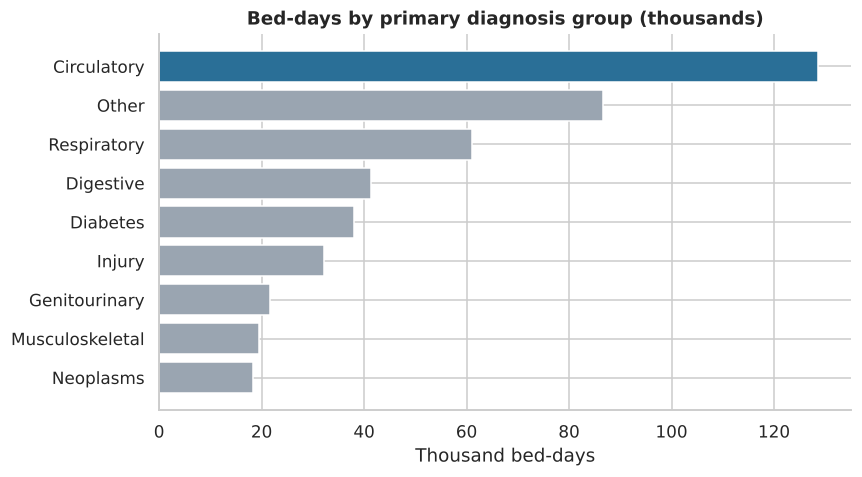

In [9]:
res_diag = df.groupby("diag_group").agg(encounters=("encounter_id", "size"), bed_days=("length_of_stay", "sum"),
                                        avg_meds=("num_medications", "mean"), avg_labs=("num_lab_procedures", "mean")).sort_values("bed_days", ascending=False)
res_diag["bed_day_share_pct"] = (res_diag.bed_days / res_diag.bed_days.sum() * 100).round(1)
res_diag = res_diag.round(1); res_diag.to_csv(OUT / "summary_resources_by_diagnosis.csv")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(res_diag.index[::-1], res_diag.bed_days[::-1] / 1000, color=[BLUE if i < 1 else GREY for i in range(len(res_diag))][::-1])
ax.set(title="Bed-days by primary diagnosis group (thousands)", xlabel="Thousand bed-days")
save(fig, "q5_bed_days_by_diagnosis")
readm_beds = df[df.readmitted == "<30"].length_of_stay.sum()
spec = df.groupby("specialty_group").agg(encounters=("encounter_id", "size"), bed_days=("length_of_stay", "sum")).sort_values("bed_days", ascending=False)
display(res_diag); display(spec)
by_prior = df.groupby("prior_inpatient_band").agg(patients_share=("encounter_id", "size"), bed_days=("length_of_stay", "sum")).reindex(["0", "1", "2", "3+"])
by_prior = (by_prior / by_prior.sum() * 100).round(1); display(by_prior)

## Key findings (generated from the numbers above)

In [10]:
k = kpi; lr_r, gb_r = res["logistic_regression"], res["gradient_boosting"]
findings = [
 f"{k['encounters']:,} encounters from {k['unique_patients']:,} patients; average stay {k['avg_los_days']} days (median {k['median_los_days']:.0f}); "
 f"30-day readmission rate {k['readmission_rate_30d_pct']}% ({k['readmissions_30d']:,} of {k['readmit_eligible']:,} eligible).",
 f"Prior inpatient use is the strongest signal: {r_prior.loc['0','rate_pct']}% readmitted with no inpatient stay in the prior year vs {r_prior.loc['3+','rate_pct']}% with 3 or more.",
 f"Discharge destination matters: {r_disp.loc['Nursing/rehab facility','rate_pct']}% for nursing/rehab facilities and {r_disp.loc['Other facility','rate_pct']}% for other facilities vs {r_disp.loc['Home','rate_pct']}% for home.",
 f"HbA1c was measured in only {k['a1c_tested_pct']}% of encounters; tested patients were readmitted at {rate('a1c_tested').loc[True,'rate_pct']}% vs {rate('a1c_tested').loc[False,'rate_pct']}%.",
 f"Circulatory conditions use {res_diag.loc['Circulatory','bed_day_share_pct']}% of all {k['total_bed_days']:,} bed-days.",
 f"Risk model (patient-grouped hold-out): logistic AUC {lr_r['auc']}, gradient boosting AUC {gb_r['auc']}; the top-risk 10% are readmitted at {gb_r['top_decile_rate_pct']}% "
 f"({gb_r['lift']}x the base rate) and hold {gb_r['top_decile_share_pct']}% of readmissions.",
]
for i, f in enumerate(findings, 1): print(f"{i}. {f}")

1. 101,763 encounters from 71,515 patients; average stay 4.4 days (median 4); 30-day readmission rate 11.39% (11,314 of 99,340 eligible).
2. Prior inpatient use is the strongest signal: 8.6% readmitted with no inpatient stay in the prior year vs 26.4% with 3 or more.
3. Discharge destination matters: 15.9% for nursing/rehab facilities and 19.1% for other facilities vs 9.3% for home.
4. HbA1c was measured in only 16.7% of encounters; tested patients were readmitted at 9.9% vs 11.7%.
5. Circulatory conditions use 28.8% of all 447,352 bed-days.
6. Risk model (patient-grouped hold-out): logistic AUC 0.659, gradient boosting AUC 0.663; the top-risk 10% are readmitted at 26.0% (2.27x the base rate) and hold 22.7% of readmissions.


### Recommendations
1. **Flag frequent inpatients at discharge** — patients with 2 or more inpatient stays in the past year are readmitted at 17.9–26.4%, versus 8.6% for patients with none; give them a follow-up call and an early clinic appointment.
2. **Strengthen hand-offs to nursing and rehab facilities** — these discharges are readmitted far more often than discharges home; share medication lists and a follow-up plan with the receiving facility.
3. **Measure HbA1c more consistently** — it was recorded in fewer than 1 in 5 diabetic encounters; tested patients were readmitted less often (association, consistent with Strack et al. 2014).
4. **Use the risk score to rank, not to decide** — an AUC of about 0.66 is useful for prioritising follow-up lists, not for individual clinical decisions.

*Caveats: observational data from 1999–2008; readmissions to other hospitals may be missed; associations, not causes.*